<a href="https://colab.research.google.com/github/YonaUz/RAG-and-LLM/blob/main/02_document_splitting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install -U langchain-text-splitters tiktoken

In [2]:
import json
from pathlib import Path
from collections import Counter

import tiktoken

from langchain_core.documents import Document
from langchain_text_splitters import (
    RecursiveCharacterTextSplitter,
    TokenTextSplitter,
)

In [3]:
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Satellite_Intelligence_Assistant"
)

PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"

INPUT_FILE = PROCESSED_DATA_DIR / "ingested_documents.jsonl"
OUTPUT_FILE = PROCESSED_DATA_DIR / "split_documents.jsonl"

print(f"Input file: {INPUT_FILE}")
print(f"Output file: {OUTPUT_FILE}")

assert INPUT_FILE.exists(), "The ingested documents file was not found."

Input file: /content/drive/MyDrive/Satellite_Intelligence_Assistant/data/processed/ingested_documents.jsonl
Output file: /content/drive/MyDrive/Satellite_Intelligence_Assistant/data/processed/split_documents.jsonl


In [4]:
documents = []

with INPUT_FILE.open("r", encoding="utf-8") as file:
    for line in file:
        record = json.loads(line)

        document = Document(
            page_content=record["page_content"],
            metadata=record["metadata"],
        )

        documents.append(document)

print(f"Loaded documents: {len(documents)}")

Loaded documents: 269


In [5]:
# Instead of loading large pdf files, we saved a jsonl file
# and retrieve the content
print("First document preview:")
print(documents[0].page_content[:500])

print("\nMetadata:")
print(documents[0].metadata)

First document preview:
LSDS-1574 
Version 5.0 
Department of the Interior 
U.S. Geological Survey 
 
 
 
 
 
Landsat 8 (L8) 
Data Users Handbook 
 
 
 
 
 
 
 
 
 
 
 
 
 
Version 5.0 
 
November 2019

Metadata:
{'producer': 'Adobe PDF Library 19.21.79', 'creator': 'Acrobat PDFMaker 19 for Word', 'creationdate': '2019-11-19T10:06:32-06:00', 'author': 'aaker', 'company': 'EROS Data Center', 'moddate': '2019-11-26T15:30:49-06:00', 'sourcemodified': 'D:20191119160605', 'title': 'Landsat 8 Data Users Handbook', 'source': 'landsat_8_data_users_handbook.pdf', 'total_pages': 114, 'page': 0, 'page_label': '1', 'publisher': 'USGS', 'mission': 'Landsat 8', 'document_type': 'technical_handbook', 'url': 'https://www.usgs.gov/media/files/landsat-8-data-users-handbook', 'language': 'en', 'local_path': '/content/drive/MyDrive/Satellite_Intelligence_Assistant/data/raw/landsat/landsat_8_data_users_handbook.pdf', 'ingestion_date': '2026-11-09'}


## 1- Method 1 Recursive Character Splitting
The first method for splitting the text in chunks will be the Recursive Character Splitting.

In [6]:
recursive_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=150,
    length_function=len,
    separators=["\n\n", "\n", " ", ""],
)

In [7]:
chunks = recursive_splitter.split_documents(documents)

print(f"Original documents: {len(documents)}")
print(f"Generated chunks: {len(chunks)}")

Original documents: 269
Generated chunks: 698


In [8]:
for index, chunk in enumerate(chunks[:3]):
    print(f"\n{'=' * 60}")
    print(f"Chunk {index + 1}")
    print(f"{'=' * 60}")

    print(f"Content length: {len(chunk.page_content)} characters")
    print(f"Metadata: {chunk.metadata}")
    print("\nContent preview:")
    print(chunk.page_content[:700])


Chunk 1
Content length: 177 characters
Metadata: {'producer': 'Adobe PDF Library 19.21.79', 'creator': 'Acrobat PDFMaker 19 for Word', 'creationdate': '2019-11-19T10:06:32-06:00', 'author': 'aaker', 'company': 'EROS Data Center', 'moddate': '2019-11-26T15:30:49-06:00', 'sourcemodified': 'D:20191119160605', 'title': 'Landsat 8 Data Users Handbook', 'source': 'landsat_8_data_users_handbook.pdf', 'total_pages': 114, 'page': 0, 'page_label': '1', 'publisher': 'USGS', 'mission': 'Landsat 8', 'document_type': 'technical_handbook', 'url': 'https://www.usgs.gov/media/files/landsat-8-data-users-handbook', 'language': 'en', 'local_path': '/content/drive/MyDrive/Satellite_Intelligence_Assistant/data/raw/landsat/landsat_8_data_users_handbook.pdf', 'ingestion_date': '2026-11-09'}

Content preview:
LSDS-1574 
Version 5.0 
Department of the Interior 
U.S. Geological Survey 
 
 
 
 
 
Landsat 8 (L8) 
Data Users Handbook 
 
 
 
 
 
 
 
 
 
 
 
 
 
Version 5.0 
 
November 2019

Chunk 2
Content length: 

In [9]:
chunk_lengths = [
    len(chunk.page_content)
    for chunk in chunks
]
print(f"Number of chunks: {len(chunk_lengths)}")
print(f"Minimum length: {min(chunk_lengths)}")
print(f"Maximum length: {max(chunk_lengths)}")
print(f"Average length: {sum(chunk_lengths) / len(chunk_lengths):.2f}")

Number of chunks: 698
Minimum length: 69
Maximum length: 999
Average length: 798.01


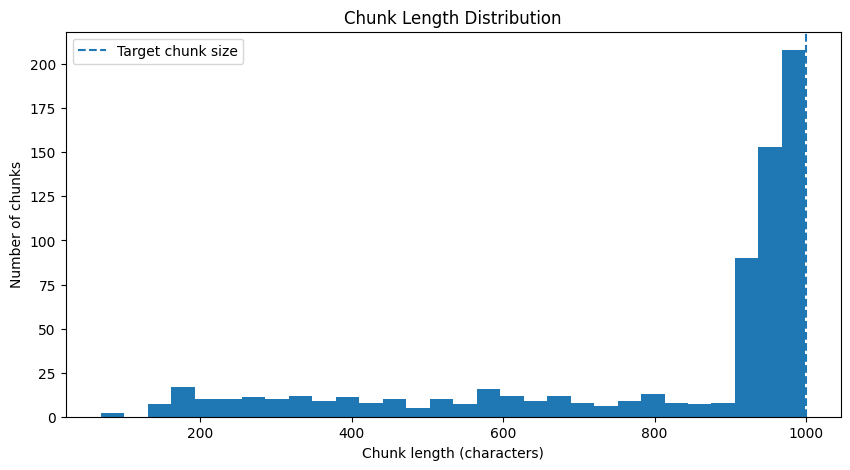

In [10]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.hist(chunk_lengths, bins=30)
plt.axvline(
    x=1000,
    linestyle="--",
    label="Target chunk size",
)
plt.xlabel("Chunk length (characters)")
plt.ylabel("Number of chunks")
plt.title("Chunk Length Distribution")
plt.legend()
plt.show()

In [11]:
for index, chunk in enumerate(chunks[:5]):
    print(
        f"Chunk {index + 1} | "
        f"Source: {chunk.metadata.get('source')} | "
        f"Page: {chunk.metadata.get('page')} | "
        f"Mission: {chunk.metadata.get('mission')}"
    )

Chunk 1 | Source: landsat_8_data_users_handbook.pdf | Page: 0 | Mission: Landsat 8
Chunk 2 | Source: landsat_8_data_users_handbook.pdf | Page: 1 | Mission: Landsat 8
Chunk 3 | Source: landsat_8_data_users_handbook.pdf | Page: 2 | Mission: Landsat 8
Chunk 4 | Source: landsat_8_data_users_handbook.pdf | Page: 2 | Mission: Landsat 8
Chunk 5 | Source: landsat_8_data_users_handbook.pdf | Page: 2 | Mission: Landsat 8


In [13]:
# until now, the chunk size was set up to 1000 and overlap 15à, we can vary the configurations
splitter_configs = {
    "small": {
        "chunk_size": 500,
        "chunk_overlap": 75,
    },
    "medium": {
        "chunk_size": 1000,
        "chunk_overlap": 150,
    },
    "large": {
        "chunk_size": 1500,
        "chunk_overlap": 225,
    },
}

In [14]:
splitting_results = {}
for config_name, config in splitter_configs.items():
    splitter = RecursiveCharacterTextSplitter(
        chunk_size=config["chunk_size"],
        chunk_overlap=config["chunk_overlap"],
        length_function=len,
    )
    split_documents = splitter.split_documents(documents)
    splitting_results[config_name] = split_documents
    print(
        f"{config_name}: "
        f"{len(split_documents)} chunks"
    )

small: 1272 chunks
medium: 698 chunks
large: 498 chunks


In [15]:
for config_name, split_documents in splitting_results.items():
    lengths = [
        len(document.page_content)
        for document in split_documents
    ]
    print(f"\nConfiguration: {config_name}")
    print(f"Number of chunks: {len(lengths)}")
    print(f"Average length: {sum(lengths) / len(lengths):.2f}")
    print(f"Maximum length: {max(lengths)}")


Configuration: small
Number of chunks: 1272
Average length: 417.97
Maximum length: 499

Configuration: medium
Number of chunks: 698
Average length: 798.01
Maximum length: 999

Configuration: large
Number of chunks: 498
Average length: 1114.43
Maximum length: 1499


## 2 - Method 2 - Token-based splitting

In [16]:
encoding = tiktoken.encoding_for_model("gpt-4o-mini")
print(f"Tokenizer encoding: {encoding.name}")

Tokenizer encoding: o200k_base


In [17]:
# previously, the splitter was RecursiveCharacterTextSplitter -
# splitting on charachers and chunk size and overlap were
# configured on the number of characters
# now, we split based on token number - the common LLM unit
token_splitter = TokenTextSplitter(
    encoding_name=encoding.name,
    chunk_size=300, # max token number
    chunk_overlap=50, # token overlap
)

In [18]:
token_chunks = token_splitter.split_documents(documents)
print(f"Token-based chunks: {len(token_chunks)}")

Token-based chunks: 608


In [19]:
for index, chunk in enumerate(token_chunks[25:30]): # [:5]: first pages & cover book; [5:15] table of contents; [25:30]
    token_count = len(
        encoding.encode(chunk.page_content)
    )
    print(f"Chunk {index + 1}")
    print(f"Token count: {token_count}")
    print(chunk.page_content[:300])
    print("-" * 50)

Chunk 1
Token count: 300
- 4 - LSDS-1574 
Version 5.0 
 
Figure 1-1. Continuity of Multispectral Data Coverage Provided by Landsat 
Missions 
1.2.2 Operations and Management 
The L8 management structure is composed of an ongoing partnership between NASA 
and USGS for sustainable land imaging. NASA contracted with Ball Aeros
--------------------------------------------------
Chunk 2
Token count: 225
 Stations (IGSs). 
USGS EROS captures L8 data and performs pre-processing, archiving, product 
generation, and distribution functions. USGS EROS also provides a public interface into 
the archive for data search and ordering. 
1.3 Landsat 8 Mission 
The L8 mission objective is to provide timely, hig
--------------------------------------------------
Chunk 3
Token count: 300
- 5 - LSDS-1574 
Version 5.0 
• Build and periodically refresh a global archive of Sun-lit, substantially cloud-free 
land images.  
1.3.2  System Capabilities 
The L8 System is robust, high performing, and of extremely h

## 3 - Method 3 - Semantic Splitting
This method relies on an embedding model from OpenAI, creates a a semantic text splitter. This method has a cost, so we just test it but will follow with another one.

In [20]:
%pip install -U langchain-experimental langchain-openai

In [21]:
import os
import getpass

from langchain_openai import OpenAIEmbeddings
from langchain_experimental.text_splitter import SemanticChunker

/tmp/ipykernel_2346/1204126360.py:5: DeprecationWarning: `langchain-experimental` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-experimental/issues/87 for details.
  from langchain_experimental.text_splitter import SemanticChunker


In [22]:
if "OPENAI_API_KEY" not in os.environ:
    os.environ["OPENAI_API_KEY"] = getpass.getpass(
        "Enter your OpenAI API key: "
    )

Enter your OpenAI API key: ··········


In [23]:
embedding_model = OpenAIEmbeddings(
    model="text-embedding-3-small"
)

In [24]:
semantic_splitter = SemanticChunker(
    embeddings=embedding_model,
    breakpoint_threshold_type="gradient",
    breakpoint_threshold_amount=0.8,
)

In [25]:
# short sample
sample_documents = documents[10:13]
semantic_chunks = semantic_splitter.split_documents(
    sample_documents
)
print(f"Semantic chunks: {len(semantic_chunks)}")
for index, chunk in enumerate(semantic_chunks[:3]):
    print(f"\nChunk {index + 1}")
    print(chunk.page_content[:500])

Semantic chunks: 52

Chunk 1
- 3 - LSDS-1574 
Version 5.0 
(U.S.

Chunk 2
Code Title 15, Chapter 82) established data continuity as a fundamental goal and 
defined continuity as providing data “sufficiently consistent (in terms of acquisition 
geometry, coverage characteristics, and spectral characteristics) with previous Landsat 
data to allow comparisons for global and regional change detection and 
characterization”.

Chunk 3
This direction has provided the guiding principal for specifying L8 
requirements from the beginning, with the most recently launched Landsat satellite at 
that time, L7, serving as a technical minimum standard for system performance and 
data quality.


In [26]:
final_chunks = splitting_results["medium"]
print(f"Selected chunks: {len(final_chunks)}")

Selected chunks: 698


In [27]:
for index, chunk in enumerate(final_chunks):
    chunk.metadata["chunk_index"] = index
    chunk.metadata["chunk_id"] = (
        f"{chunk.metadata.get('source', 'unknown')}_"
        f"{chunk.metadata.get('page', 'unknown')}_"
        f"{index}"
    )
    chunk.metadata["chunk_size"] = len(chunk.page_content)
    chunk.metadata["splitting_method"] = "recursive_character"

In [28]:
CHUNKS_FILE = PROCESSED_DATA_DIR / "split_documents.jsonl"

with CHUNKS_FILE.open("w", encoding="utf-8") as file:
    for chunk in final_chunks:
        record = {
            "page_content": chunk.page_content,
            "metadata": chunk.metadata,
        }
        file.write(
            json.dumps(record, ensure_ascii=False) + "\n"
        )
print(f"Saved {len(final_chunks)} chunks.")
print(f"Output file: {CHUNKS_FILE}")

Saved 698 chunks.
Output file: /content/drive/MyDrive/Satellite_Intelligence_Assistant/data/processed/split_documents.jsonl


In [29]:
# We save the medium configuration chunks for not having to recreate them, in the next notebook we will just have to load the file
reloaded_chunks = []
with CHUNKS_FILE.open("r", encoding="utf-8") as file:
    for line in file:
        record = json.loads(line)
        chunk = Document(
            page_content=record["page_content"],
            metadata=record["metadata"],
        )
        reloaded_chunks.append(chunk)
print(f"Reloaded chunks: {len(reloaded_chunks)}")
assert len(reloaded_chunks) == len(final_chunks)
print("Chunk persistence check passed.")

Reloaded chunks: 698
Chunk persistence check passed.
